# 03 LightGBM Baseline

The purpose of a baseline is a reference against which later feature and parameter changes can be measured one at a time.


In [2]:
from pathlib import Path

def find_project_root() -> Path:
    """Use the parent of the notebook working directory as the project root."""
    project_root = Path.cwd().resolve().parent
    if not (project_root / 'data').is_dir():
        raise FileNotFoundError(
            "Expected the project data directory one level above the current working directory."
        )
    return project_root

import gc
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    log_loss,
    roc_auc_score,
    RocCurveDisplay,
)

pd.set_option('display.max_rows', 100)
print('Python:', platform.python_version())
print('LightGBM:', lgb.__version__)


Python: 3.10.19
LightGBM: 4.7.0


### 1. Configure paths and dependencies


In [ ]:
PROJECT_ROOT = find_project_root()
STEP_DIR = PROJECT_ROOT / '03_baseline'
DATA_PATH = PROJECT_ROOT / '02_aggregation' / 'train_aggregated.parquet'
LABEL_PATH = PROJECT_ROOT / 'data' / 'train_labels.csv'
MODEL_PATH = STEP_DIR / 'lightgbm_baseline.txt'
PREDICTION_PATH = STEP_DIR / 'lightgbm_validation_predictions.parquet'
IMPORTANCE_PATH = STEP_DIR / 'baseline_feature_importance.csv'

assert DATA_PATH.exists(), f'找不到 {DATA_PATH.resolve()}'
assert LABEL_PATH.exists(), f'找不到 {LABEL_PATH.resolve()}'

print(f'Aggregated data: {DATA_PATH.resolve()}')
print(f'File size: {DATA_PATH.stat().st_size / 2**30:.2f} GiB')


### 2. The feature matrix

`customer_ID` is an identifier, not a behavioral measurement, so it is excluded. `S_2_last` becomes the number of days relative to `2018-03-01`.

The 11 `*_last` categorical columns are cast to pandas `category`, allowing LightGBM to use native categorical splits. Remaining missing values are left intact because LightGBM can learn default directions for them.


In [4]:
data = pd.read_parquet(DATA_PATH)
print(f'Loaded：{data.shape[0]:,} rows × {data.shape[1]:,} columns')

customer_ids = data.pop('customer_ID')
y = data.pop('target').astype('int8')

data['S_2_last'] = (
    pd.to_datetime(data['S_2_last']) - pd.Timestamp('2018-03-01')
).dt.days.astype('int16')

ORIGINAL_CATEGORICAL_COLUMNS = [
    'B_30', 'B_38', 'D_114', 'D_116', 'D_117', 'D_120',
    'D_126', 'D_63', 'D_64', 'D_66', 'D_68'
]
CATEGORICAL_FEATURES = [f'{column}_last' for column in ORIGINAL_CATEGORICAL_COLUMNS]

for column in CATEGORICAL_FEATURES:
    data[column] = data[column].astype('category')

X = data
del data
gc.collect()

print(f'Model feature count：{X.shape[1]}')
print(f'Categorical feature count：{len(CATEGORICAL_FEATURES)}')
print('Target distribution：')
display(y.value_counts(normalize=True).sort_index().rename('ratio').to_frame())


Loaded：458,913 rows × 899 columns
Model feature count：897
Categorical feature count：11
Target distribution：


,ratio
target,
0,0.741066
1,0.258934


### 3. Train-test split

The split is stratified to preserve the default rate in both subsets and uses `random_state=42` for  reproducibility. Because aggregation already produced one row per customer, row-level splitting here is same as customer-level splitting.


In [5]:
all_indices = np.arange(len(X))
train_indices, valid_indices = train_test_split(
    all_indices,
    train_size=0.70,
    test_size=0.30,
    random_state=42,
    stratify=y,
)

X_train = X.iloc[train_indices].copy()
X_valid = X.iloc[valid_indices].copy()
y_train = y.iloc[train_indices].copy()
y_valid = y.iloc[valid_indices].copy()
valid_customer_ids = customer_ids.iloc[valid_indices].copy()

del X, y, customer_ids, all_indices, train_indices, valid_indices
gc.collect()

split_summary = pd.DataFrame({
    'rows': [len(X_train), len(X_valid)],
    'percentage': [len(X_train) / (len(X_train) + len(X_valid)), len(X_valid) / (len(X_train) + len(X_valid))],
    'target_1_rate': [y_train.mean(), y_valid.mean()],
}, index=['train', 'validation'])
display(split_summary)


,rows,percentage,target_1_rate
train,321239,0.7,0.258935
validation,137674,0.3,0.258931


### 4. Train the baseline model

A low learning rate builds trees gradually, while `max_bin=127` and four worker threads limit resource use. Early stopping monitors validation ROC-AUC and stops after 100 rounds without improvement, selecting the best iteration instead of the final allowed tree.


In [6]:
model = lgb.LGBMClassifier(
    objective='binary',
    n_estimators=1500,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=100,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    max_bin=127,
    random_state=42,
    n_jobs=4,
    verbosity=-1,
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_valid, y_valid)],
    eval_metric='auc',
    categorical_feature=CATEGORICAL_FEATURES,
    callbacks=[
        lgb.early_stopping(stopping_rounds=100, verbose=True),
        lgb.log_evaluation(period=50),
    ],
)

print('Best iteration:', model.best_iteration_)


/opt/anaconda3/envs/cs178/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[50]	valid_0's auc: 0.951214	valid_0's binary_logloss: 0.289477
[100]	valid_0's auc: 0.955348	valid_0's binary_logloss: 0.244059
[150]	valid_0's auc: 0.957675	valid_0's binary_logloss: 0.231262
[200]	valid_0's auc: 0.959165	valid_0's binary_logloss: 0.225724
[250]	valid_0's auc: 0.960075	valid_0's binary_logloss: 0.222717
[300]	valid_0's auc: 0.960669	valid_0's binary_logloss: 0.220815
[350]	valid_0's auc: 0.961075	valid_0's binary_logloss: 0.219554
[400]	valid_0's auc: 0.961339	valid_0's binary_logloss: 0.218738
[450]	valid_0's auc: 0.961494	valid_0's binary_logloss: 0.218264
[500]	valid_0's auc: 0.961588	valid_0's binary_logloss: 0.217975
[550]	valid_0's auc: 0.961651	valid_0's binary_logloss: 0.21778
[600]	valid_0's auc: 0.961713	valid_0's binary_logloss: 0.217594
[650]	valid_0's auc: 0.961762	valid_0's binary_logloss: 0.217441
[700]	valid_0's auc: 0.961792	valid_0's binary_logloss: 0.217354
[750]	valid_0's auc: 0.961816	

### 5. Evaluate validation performance

ROC-AUC measures ranking quality across all thresholds; log loss penalizes poorly calibrated, overconfident errors; accuracy is reported only as a familiar secondary statistic.

Later experiments add the official AMEX metric, which places extra emphasis on capturing defaults at the top of the risk ranking.


,validation_score
roc_auc,0.961924
log_loss,0.216917
accuracy_at_0.5,0.904034


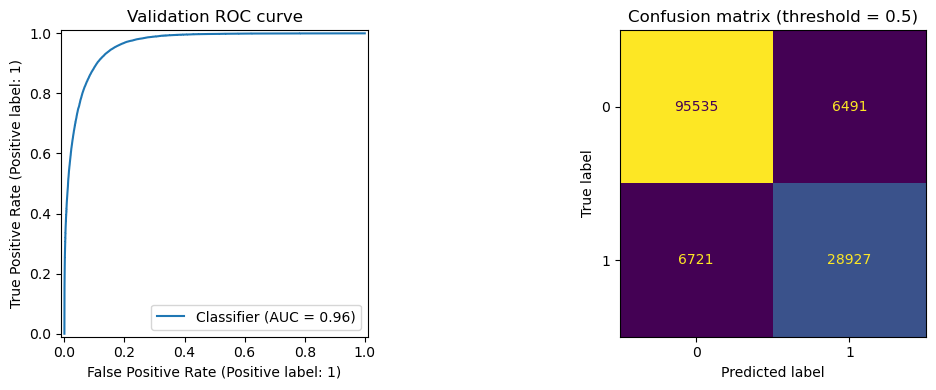

In [7]:
valid_probability = model.predict_proba(
    X_valid,
    num_iteration=model.best_iteration_,
)[:, 1]
valid_prediction = (valid_probability >= 0.5).astype('int8')

metrics = {
    'roc_auc': roc_auc_score(y_valid, valid_probability),
    'log_loss': log_loss(y_valid, valid_probability),
    'accuracy_at_0.5': accuracy_score(y_valid, valid_prediction),
}
display(pd.Series(metrics, name='validation_score').to_frame())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_valid, valid_probability, ax=axes[0])
ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_valid, valid_prediction)
).plot(ax=axes[1], colorbar=False)
axes[0].set_title('Validation ROC curve')
axes[1].set_title('Confusion matrix (threshold = 0.5)')
plt.tight_layout()
plt.show()


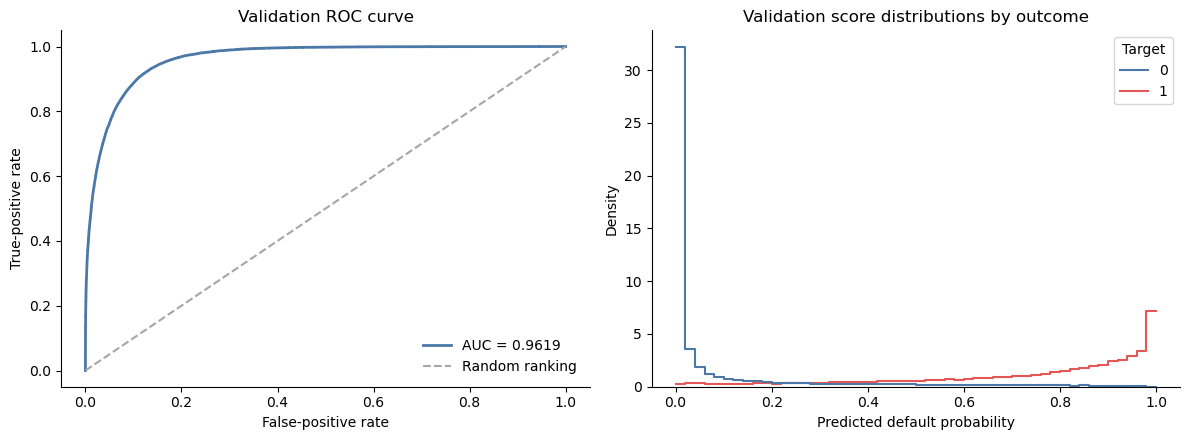

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Validation discrimination and score separation
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_valid, valid_probability)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(fpr, tpr, color='#4C78A8', linewidth=2, label=f'AUC = {metrics["roc_auc"]:.4f}')
axes[0].plot([0, 1], [0, 1], '--', color='0.65', label='Random ranking')
axes[0].set(title='Validation ROC curve', xlabel='False-positive rate', ylabel='True-positive rate')
axes[0].legend(frameon=False)

score_frame = pd.DataFrame({'Predicted default probability': valid_probability, 'Target': y_valid.to_numpy()})
sns.histplot(data=score_frame, x='Predicted default probability', hue='Target', bins=50,
             stat='density', common_norm=False, element='step', fill=False, ax=axes[1],
             palette=['#4C78A8', '#E45756'])
axes[1].set(title='Validation score distributions by outcome', ylabel='Density')
sns.despine()
plt.tight_layout()
plt.show()


### 6. Inspect gain importance

Gain importance sums the training loss reduction attributed to each feature. 


,feature,gain,split,gain_percentage
708,P_2_last,2.237389e+06,509,0.520611
0,P_2_mean,1.978177e+05,185,0.046030
710,B_1_last,1.941470e+05,133,0.045175
711,B_2_last,7.494035e+04,100,0.017438
732,B_9_last,7.074795e+04,100,0.016462
712,R_1_last,6.863350e+04,136,0.015970
2,P_2_min,6.676933e+04,139,0.015536
709,D_39_last,6.518992e+04,344,0.015169
739,B_11_last,4.788993e+04,160,0.011143
718,D_44_last,3.802875e+04,161,0.008849


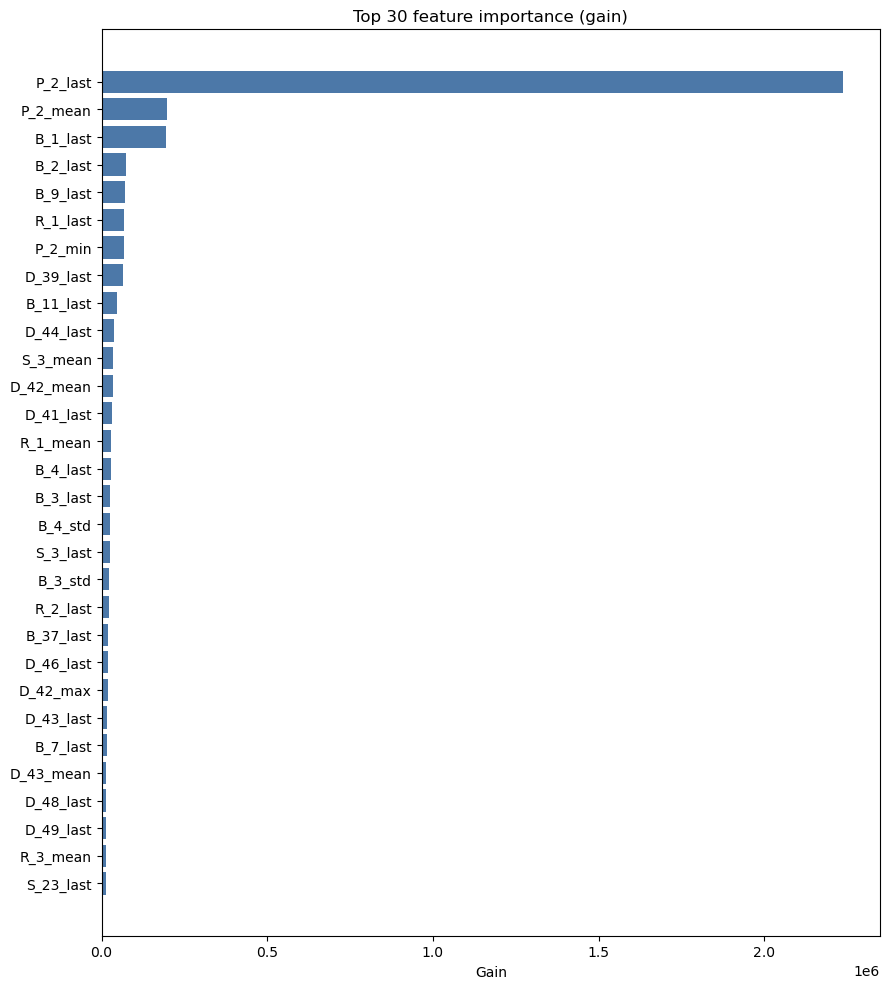

In [9]:
feature_importance = pd.DataFrame({
    'feature': model.booster_.feature_name(),
    'gain': model.booster_.feature_importance(importance_type='gain'),
    'split': model.booster_.feature_importance(importance_type='split'),
}).sort_values('gain', ascending=False)
feature_importance['gain_percentage'] = (
    feature_importance['gain'] / feature_importance['gain'].sum()
)

display(feature_importance.head(30))

top_features = feature_importance.head(30).sort_values('gain')
plt.figure(figsize=(9, 10))
plt.barh(top_features['feature'], top_features['gain'], color='#4C78A8')
plt.title('Top 30 feature importance (gain)')
plt.xlabel('Gain')
plt.tight_layout()
plt.show()


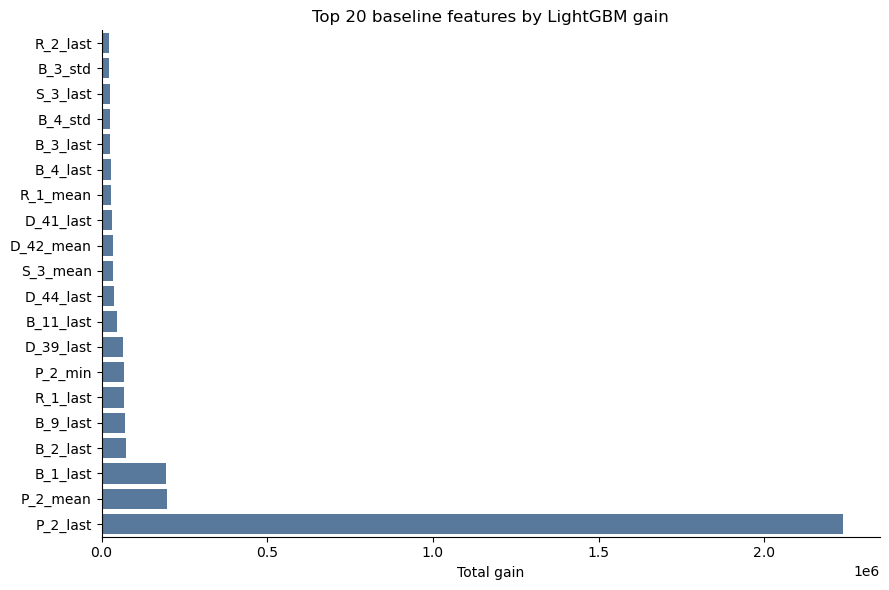

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Top baseline features by gain
top_gain = feature_importance.head(20).sort_values('gain')
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=top_gain, y='feature', x='gain', color='#4C78A8', ax=ax)
ax.set(title='Top 20 baseline features by LightGBM gain', xlabel='Total gain', ylabel='')
sns.despine()
plt.tight_layout()
plt.show()


### 7. Save artifacts

The best booster, feature importance table, and row-level validation predictions are saved. 

In [ ]:
model.booster_.save_model(MODEL_PATH, num_iteration=model.best_iteration_)
feature_importance.to_csv(IMPORTANCE_PATH, index=False)

validation_predictions = pd.DataFrame({
    'customer_ID': valid_customer_ids.to_numpy(),
    'target': y_valid.to_numpy(),
    'prediction_probability': valid_probability.astype('float32'),
    'prediction_at_0.5': valid_prediction,
})
validation_predictions.to_parquet(PREDICTION_PATH, index=False, compression='zstd')

run_summary = {
    'train_rows': len(X_train),
    'validation_rows': len(X_valid),
    'number_of_features': X_train.shape[1],
    'best_iteration': model.best_iteration_,
    **metrics,
}
(STEP_DIR / 'lightgbm_baseline_metrics.json').write_text(
    json.dumps(run_summary, indent=2),
    encoding='utf-8',
)

print('Model:', MODEL_PATH.resolve())
print('Validation predictions:', PREDICTION_PATH.resolve())
print('Feature importance:', IMPORTANCE_PATH.resolve())
print('Metrics:', (STEP_DIR / 'lightgbm_baseline_metrics.json').resolve())
